# ADPLL design report

All-digital, injection-capable PLL (`src/pll.v`): a ring DCO with coarse/mid/fine delay lines, a
sub-sampling bang-bang phase detector (SS-BBPD), a PI digital loop filter with a 1st-order
$\Delta\Sigma$ on the fine code, and optional edge injection of the reference (IL-PLL / MDLL mode).
The architecture follows [IEEE 8686112](https://ieeexplore.ieee.org/document/8686112).

**Everything in this notebook is computed from the latest results of the flow** in
`sim/outputs/<PDK>/`. Nothing is typed in by hand except the assumptions listed in *Setup*.

| Level | Tool | What it gives | Used for |
|---|---|---|---|
| 1. Transistor level | ngspice | delay of each cell vs code, mux/SS-BBPD/injection timing, DCO phase noise (ISF) | the parameters of every model below |
| 2. Linear model | Python (`pll_model.LinearModel`) | loop gain, bandwidth, margins, noise transfer functions, phase-noise budget | design (fast, explains *why*) |
| 3. Behavioral model | Python (`pll_model.simulate`) | time-domain edges with the integer arithmetic of the RTL, sign() detector, $\Delta\Sigma$, noise | jitter including the nonlinear effects (limit cycles), KP/KI optimization |
| 4. RTL simulation | iverilog (`test_pll_digital[_inj]`) | the real RTL with delay models of level 1 (no noise) | lock, glitch check, validation of level 3 |

Regenerate the inputs with:
```sh
make -C sim PDK=ics55 test_fine_delay test_mid_delay test_coarse_delay test_pll_injection test_sym_delay
make -C sim PDK=ics55 test_dco_noise                          # DCO phase noise (ISF)
make -C sim PDK=ics55 test_pll_digital test_pll_digital_inj   # RTL, without and with injection
```

## Setup

In [1]:
import os, re, sys
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace
from IPython.display import Markdown, display

sys.path.insert(0, os.path.abspath("."))
import pll_model as pm

PDK = os.environ.get("PDK", "ics55")
SIM_OUT = os.path.abspath(os.environ.get("PLL_SIM_OUT", f"../sim/outputs/{PDK}"))
OUT_DIR = os.path.join(SIM_OUT, "report"); os.makedirs(OUT_DIR, exist_ok=True)

# --- Assumptions (not simulated): change them here ---
REF = pm.RefNoise(floor_dBc=-150, L_1k_dBc=-130)   # Reference (crystal + input buffer) phase noise at f_REF
SIGMA_BBPD = 0.3e-12                                # rms input-referred noise of the SS-BBPD (s)
JITTER_BAND = (10e3, 100e6)                         # Integration band of the rms jitter

# Plot style (fixed series colors: the same source has the same color in every plot)
COL = dict(DCO="#2a78d6", REF="#eb6834", BBPD="#1baf7a", DSM="#eda100", Total="#0b0b0b", free="#8a8984",
           sim="#6250d6", rtl="#e34948", inj="#2a78d6", noinj="#eb6834")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 1.6, "legend.frameon": False,
                     "font.size": 9})
def save(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name + ".pdf"), bbox_inches="tight")

def ps(x): return f"{x*1e12:.3g} ps"
def fs(x): return f"{x*1e15:.0f} fs"
def table(rows, head=("Quantity", "Value")):
    s = "| " + " | ".join(head) + " |\n|" + "---|" * len(head) + "\n"
    s += "\n".join("| " + " | ".join(str(c) for c in r) + " |" for r in rows)
    display(Markdown(s))

ch = pm.load_characterization(SIM_OUT)
print("Characterization:", ch.source)

Characterization: /home/ckdur/Documents/SymbioticEDA/adpll_gen/sim/outputs/ics55


In [2]:
# Configuration of the RTL simulation (src/pll_test.v), so the notebook analyzes what was simulated
tb = open("pll_test.v").read()
def get(name, default=None):
    m = re.search(rf"define\s+TB_{name}\s+'d(\d+)", tb) or re.search(rf"\b{name}\s*=\s*'d(\d+)", tb)
    return int(m.group(1)) if m else default
# Acquisition gains, and the gains after LOCKED (gear shifting) if the testbench defines them
KP_ACQ, KI_ACQ = get("KP"), get("KI")
KP_LCK, KI_LCK = get("KP_LOCKED", KP_ACQ), get("KI_LOCKED", KI_ACQ)
# The analysis is done at the operating point: the gains after LOCKED
cfg = pm.PLLConfig(f_ref=1 / (int(re.search(r"REF_T\s*=\s*(\d+)", tb).group(1)) * 1e-15),
                   KP=KP_LCK, KI=KI_LCK, N=get("FCW") + 2, sigma_bbpd=SIGMA_BBPD)
table([("f_REF", f"{cfg.f_ref/1e6:g} MHz"), ("N (FCW + 2)", cfg.N), ("f_OUT", f"{cfg.f_out/1e9:g} GHz"),
       ("KP, KI during the acquisition (filter LSB)", f"{KP_ACQ}, {KI_ACQ}"),
       ("KP, KI after LOCKED (analyzed below)", f"{cfg.KP}, {cfg.KI}" + ("" if (KP_LCK, KI_LCK) != (KP_ACQ, KI_ACQ) else " (no gear shifting)")), ("Filter / fine-code bits", f"{cfg.filter_bits} / {cfg.fine_bits}"),
       ("Filter LSB per fine code", cfg.code_lsb), ("Fine code modulation", "1st-order ΔΣ at f_OUT/2"),
       ("Reference phase noise (assumed)", f"floor {REF.floor_dBc} dBc/Hz, {REF.L_1k_dBc} dBc/Hz at 1 kHz"),
       ("SS-BBPD input noise (assumed)", ps(SIGMA_BBPD))], ("Parameter", "Value"))

# RTL simulations (iverilog, section 6), if they exist
RTL = {}
for inj, name in ((False, "test_pll_edges.txt"), (True, "test_pll_inj_edges.txt")):
    p = os.path.join(SIM_OUT, name)
    if os.path.exists(p):
        RTL[inj] = pm.analyze_rtl(p, cfg.f_ref, cfg.N, tmux=ch.tmux)
print("RTL results:", {("injection" if k else "no injection"): v["file"] for k, v in RTL.items()} or "none")

| Parameter | Value |
|---|---|
| f_REF | 100 MHz |
| N (FCW + 2) | 10 |
| f_OUT | 1 GHz |
| KP, KI during the acquisition (filter LSB) | 3967, 257 |
| KP, KI after LOCKED (analyzed below) | 3967, 257 (no gear shifting) |
| Filter / fine-code bits | 16 / 5 |
| Filter LSB per fine code | 2048 |
| Fine code modulation | 1st-order ΔΣ at f_OUT/2 |
| Reference phase noise (assumed) | floor -150 dBc/Hz, -130 dBc/Hz at 1 kHz |
| SS-BBPD input noise (assumed) | 0.3 ps |

RTL results: {'no injection': '/home/ckdur/Documents/SymbioticEDA/adpll_gen/sim/outputs/ics55/test_pll_edges.txt', 'injection': '/home/ckdur/Documents/SymbioticEDA/adpll_gen/sim/outputs/ics55/test_pll_inj_edges.txt'}


## 1. DCO: tuning characteristic

The DCO is a single-ended ring: `OUT → COARSE → MID → FINE → (balancing inverter + symmetric mux) → OUT`,
so the half period is $T/2 = t_{coarse}(c) + t_{mid}(m) + t_{fine}(f) + t_{mux}$, with the delays of each line
measured in ngspice for every thermometer code. The frequency acquisition (`freq_lock.v`) sets coarse/mid
and the loop filter drives the fine line through the $\Delta\Sigma$.

Requirements for a continuous tuning curve: **fine range > one mid step** and **mid range > one coarse step**
(otherwise there are frequencies that cannot be reached).

| Quantity | Value |
|---|---|
| Fine LSB (period) | 414 fs  →  K_DCO = 414 kHz/code (414 ppm) |
| Fine DNL (max |step/mean − 1|) | 0.38 LSB |
| Fine range (period) / mid step (period, max) | 12.83 ps / 10.96 ps  →  OK |
| Mid range / coarse step (max) | 35.4 ps / 25.1 ps  →  OK |
| Tuning range (all codes) | 0.755 – 1.841 GHz |

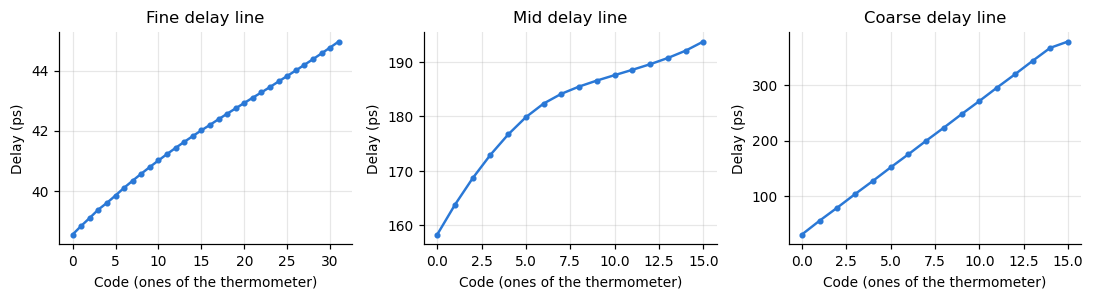

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(10, 2.8))
for a, (name, d) in zip(ax, (("Fine", ch.fine), ("Mid", ch.mid), ("Coarse", ch.coarse))):
    a.plot(np.arange(len(d)), d * 1e12, "o-", ms=3, color=COL["DCO"])
    a.set_title(f"{name} delay line"); a.set_xlabel("Code (ones of the thermometer)"); a.set_ylabel("Delay (ps)")
fig.tight_layout(); save(fig, "dco_delays")

fine_step = np.diff(ch.fine); mid_step = np.diff(ch.mid); coarse_step = np.diff(ch.coarse)
f0 = cfg.f_out
Kdco = f0 ** 2 * ch.fine_lsb                       # Hz per fine code (dT = 2 dt_fine)
table([
    ("Fine LSB (period)", f"{ch.fine_lsb*1e15:.0f} fs  →  K_DCO = {Kdco/1e3:.0f} kHz/code ({Kdco/f0*1e6:.0f} ppm)"),
    ("Fine DNL (max |step/mean − 1|)", f"{np.max(np.abs(fine_step/fine_step.mean()-1)):.2f} LSB"),
    ("Fine range (period) / mid step (period, max)", f"{2*np.ptp(ch.fine)*1e12:.2f} ps / {2*mid_step.max()*1e12:.2f} ps  →  "
     + ("OK" if np.ptp(ch.fine) > mid_step.max() else "**GAP: fine range < mid step**")),
    ("Mid range / coarse step (max)", f"{np.ptp(ch.mid)*1e12:.1f} ps / {coarse_step.max()*1e12:.1f} ps  →  "
     + ("OK" if np.ptp(ch.mid) > coarse_step.max() else "**GAP: mid range < coarse step**")),
    ("Tuning range (all codes)", f"{1/ch.period(15,15,31)/1e9:.3f} – {1/ch.period(0,0,0)/1e9:.3f} GHz"),
])

f_OUT = 1 GHz: best coarse = 8, mid = 13, fine code ≈ 13.7 of 31
The RTL acquisition chose coarse = 8, mid = 14 (fine code ≈ 7.2): used from here on


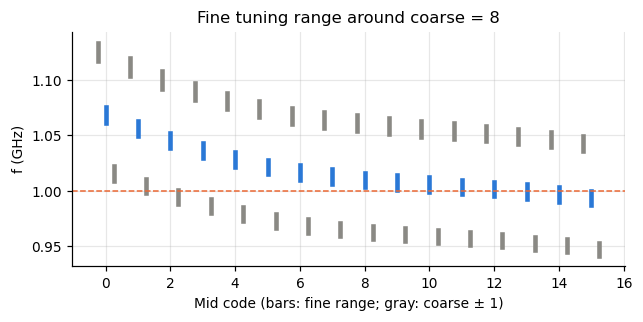

In [4]:
# Coarse/mid codes that place f_OUT closest to the center of the fine range (what the acquisition targets)
best = None
for c in range(len(ch.coarse)):
    for m in range(len(ch.mid)):
        lo, hi = ch.period(c, m, 0), ch.period(c, m, len(ch.fine) - 1)
        if lo <= 1 / f0 <= hi:
            r = (1 / f0 - lo) / (hi - lo)
            if best is None or abs(r - 0.5) < abs(best[2] - 0.5):
                best = (c, m, r)
COARSE, MID, frac = best
COARSE_C, MID_C = COARSE, MID     # Target in the middle of the fine range (used for the pull-in analysis)
print(f"f_OUT = {f0/1e9:g} GHz: best coarse = {COARSE}, mid = {MID}, fine code ≈ {frac*(len(ch.fine)-1):.1f} of {len(ch.fine)-1}")
if False in RTL and RTL[False].get("coarse") is not None:
    COARSE, MID = RTL[False]["coarse"], RTL[False]["mid"]
    lo, hi = ch.period(COARSE, MID, 0), ch.period(COARSE, MID, len(ch.fine) - 1)
    frac = (1 / f0 - lo) / (hi - lo)
    print(f"The RTL acquisition chose coarse = {COARSE}, mid = {MID} (fine code ≈ {frac*(len(ch.fine)-1):.1f}): used from here on")

fig, a = plt.subplots(figsize=(6, 3))
for c in range(max(0, COARSE - 1), min(len(ch.coarse), COARSE + 2)):
    for m in range(len(ch.mid)):
        fr = 1 / ch.period(c, m, np.array([0, len(ch.fine) - 1])) / 1e9
        a.plot([m + (c - COARSE) * 0.25] * 2, fr, color=COL["DCO"] if c == COARSE else COL["free"], lw=3)
a.axhline(f0 / 1e9, color=COL["REF"], ls="--", lw=1)
a.set_xlabel("Mid code (bars: fine range; gray: coarse ± 1)"); a.set_ylabel("f (GHz)")
a.set_title(f"Fine tuning range around coarse = {COARSE}")
fig.tight_layout(); save(fig, "dco_tuning")

## 2. DCO phase noise (ISF, transistor level, validated with Spectre)

ngspice has no oscillator noise analysis, so the free-running phase noise comes from the Hajimiri–Lee
impulse sensitivity function (`make test_dco_noise`): the ISF $h_n(x)$ of every oscillating net
(charge-injection transient runs), combined with the cyclostationary drain-current noise of every transistor
along the period (ngspice `.noise` tables vs $V_{GS}, V_{DS}$, tabulated in frequency per device):

$$S_\phi(f) = \frac{1}{(2\pi f)^2}\sum_{dev}\Big[\overline{h_{dev}^2 S_{th}(x)} + \big(\overline{h_{dev}\sqrt{S_{fl}(f,x)}}\big)^2\Big],\qquad \mathcal{L}=S_\phi/2$$

**Validation** (`make test_dco_spectre`, optional, needs Spectre): Spectre autonomous PSS + pnoise of the same
netlist, codes and model cards. When the file exists it is overlaid below. The device noise tables of ngspice and
Spectre agree to 4 digits; the oscillator phase noise agrees within ~1 dB from 1 kHz to 100 MHz, and both
methods find the same dominant contributor. Note the high 1/f³ corner: the minimum-length devices of this
process have a drain-noise 1/f corner of hundreds of MHz, and in a ring the flicker noise of each device
modulates its own transition (it is not cancelled by symmetry).

For the loop models the result is fitted to $\mathcal{L}(f) = a/f^2 + b/f^{2+e_f}$ (white and flicker FM).

| Quantity | Value |
|---|---|
| Source | ISF simulation (test_dco_noise.csv) at 0.936 GHz, scaled to 1 GHz |
| L(1 MHz) | -83.4 dBc/Hz |
| 1/f³ corner | 10540 kHz |
| Period jitter (white part), σ_T = √(a/f0³) | 464 fs |
| Accumulated in one REF period, √N σ_T | 1467 fs |

**ISF vs Spectre** (same codes, unscaled, dBc/Hz):

| Offset | ISF (ngspice) | Spectre pnoise | Difference (dB) |
|---|---|---|---|
| 0.01 MHz | -18.5 | -17.6 | -0.9 |
| 0.1 MHz | -51.3 | -50.4 | -0.9 |
| 1 MHz | -84.0 | -83.1 | -0.8 |
| 10 MHz | -114.1 | -113.7 | -0.4 |
| 100 MHz | -137.0 | -136.9 | -0.1 |

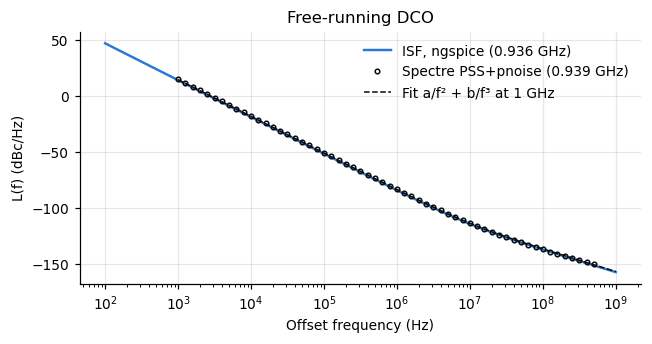

In [5]:
if ch.dco_pn is not None:
    DCO_ISF = pm.DCONoise.from_isf(ch.dco_pn)
    f_isf = ch.dco_pn_f0 or f0
    # The ISF runs at the fixed codes of test_dco.sp: scale to the operating frequency
    # (same cells, so c = sigma_T^2/T is kept and L scales with f0^2)
    DCO = DCO_ISF.scaled(f_isf, f0)
    dco_src = f"ISF simulation (test_dco_noise.csv) at {f_isf/1e9:.3f} GHz, scaled to {f0/1e9:g} GHz"
else:
    DCO = pm.DCONoise.from_dBc(-100, 1e6, corner=300e3)
    dco_src = "**PLACEHOLDER** (-100 dBc/Hz at 1 MHz, 300 kHz corner): run `make test_dco_noise`"
    display(Markdown("> **Warning:** no ISF result found, the DCO noise below is a placeholder."))
fig, a = plt.subplots(figsize=(6, 3.2))
fx = np.geomspace(1e3, 1e9, 400)
if ch.dco_pn is not None:
    a.semilogx(ch.dco_pn["freq"], ch.dco_pn["L"], color=COL["DCO"], label=f"ISF, ngspice ({f_isf/1e9:.3f} GHz)")
sp_rows = []
if ch.dco_pn_spectre is not None:
    sp = ch.dco_pn_spectre
    a.semilogx(sp["freq"], sp["L"], "o", ms=3, mfc="none", color=COL["Total"], label=f"Spectre PSS+pnoise ({(ch.dco_pn_spectre_f0 or 0)/1e9:.3f} GHz)")
    if ch.dco_pn is not None:
        for fo in (1e4, 1e5, 1e6, 1e7, 1e8):
            li = np.interp(np.log10(fo), np.log10(ch.dco_pn["freq"]), ch.dco_pn["L"])
            ls_ = np.interp(np.log10(fo), np.log10(sp["freq"]), sp["L"])
            sp_rows.append((f"{fo/1e6:g} MHz", f"{li:.1f}", f"{ls_:.1f}", f"{li-ls_:+.1f}"))
a.semilogx(fx, 10*np.log10(DCO.L(fx)), "--", color=COL["Total"], lw=1, label=f"Fit a/f² + b/f³ at {f0/1e9:g} GHz")
a.set_xlabel("Offset frequency (Hz)"); a.set_ylabel("L(f) (dBc/Hz)"); a.set_title("Free-running DCO")
a.legend(); fig.tight_layout(); save(fig, "dco_pn")
table([("Source", dco_src),
       ("L(1 MHz)", f"{10*np.log10(DCO.L(1e6)):.1f} dBc/Hz"),
       ("1/f³ corner", f"{DCO.corner/1e3:.0f} kHz"),
       ("Period jitter (white part), σ_T = √(a/f0³)", fs(DCO.period_jitter(f0))),
       ("Accumulated in one REF period, √N σ_T", fs(np.sqrt(cfg.N) * DCO.period_jitter(f0)))])
if sp_rows:
    display(Markdown("**ISF vs Spectre** (same codes, unscaled, dBc/Hz):"))
    table(sp_rows, ("Offset", "ISF (ngspice)", "Spectre pnoise", "Difference (dB)"))

## 3. Injection and SS-BBPD timing (glitch-free condition)

With injection, during a window around the (delayed) falling edge of REF the symmetric mux passes the
reference edge instead of the DCO edge. Both paths are `INV → NAND2 → NAND2`, and the SS-BBPD (a NAND
latch) arbitrates between **the same two nets** (`INJ_EDGE_BALANCED`, `OSC_BALANCED`). So the loop locks
the natural DCO edge onto the injected edge, and the injection only corrects the accumulated jitter.

The replacement is glitch-free only if the natural edge falls **inside the window**. The window is
guarded (`sym_mux.v`): it only opens if the DCO is still low, so an early DCO edge skips that injection
instead of making a runt pulse (without the guard, the transistor-level simulation shows the ring locking
on the edges of the window). A DCO edge after the end of the window still gives a runt pulse: the mux is
inside the ring, so the window cannot wait for it without risking a deadlock. The margins below are compared with the timing error at the SS-BBPD, $\sigma_e$ (section 4).
The injection is only enabled after `LOCKED`, while the detector keeps toggling (no run of 32 equal
decisions), and it is retimed on the rising edge of REF so it never starts or stops inside a window.

**Detector** (`il_dco.v`): the latch is captured with `BBPD_CK`, after it has arbitrated, and it is used while
the DCO edge is within $(c - T/2, c)$ of the injected edge ($c$ = `BBPD_CK` − injected edge), which contains the
lock point. Outside, the level of the DCO sampled at the injected edge decides. This gives a symmetric
$\pm T/2$ characteristic (full pull-in range) with the offset-free lock point of the latch.

| Quantity | Value |
|---|---|
| Window opens / injected edge / window closes (at the mux) | 58 ps / 120 ps / 213 ps |
| DCO edge earlier than the injected one by more than | 61.8 ps: this injection is skipped (no glitch) |
| DCO edge later than the injected one by more than | 93 ps: runt pulse on OUT (prevented by LOCKED/PHASE_OK) |
| SS-BBPD capture (BBPD_CK) after the injected edge | 157 ps (< T/2 = 500 ps) |
| Mux delay t_mux, SS-BBPD delay | 44.7 ps, 78 ps |

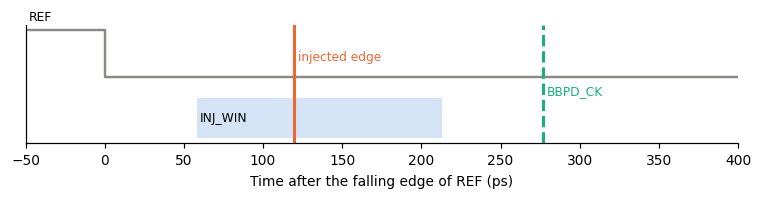

In [6]:
import spice_io
_m = spice_io.read_meas(os.path.join(SIM_OUT, "test_pll_injection.log"))
_s = spice_io.read_meas(os.path.join(SIM_OUT, "test_sym_delay.log"))
t_ck = _m.get("tbbpd_ck")
# Times at the inputs of the mux (after the REF fall): the window goes through the guard latch of sym_mux.v
# (twin_on/twin_off), the injected edge through the balancing inverter (half of tlvl, two inverters)
t_inv = _s.get("tlvl", 0.0) / 2
t_open = ch.twin_start + _s.get("twin_on", 0.0)
t_edge = ch.tedge + t_inv
t_close = ch.twin_start + ch.twin_len + _s.get("twin_off", 0.0)
early, late = t_edge - t_open, t_close - t_edge
fig, a = plt.subplots(figsize=(7, 1.9))
tt = np.array([-0.05e-9, 0, t_open, t_edge, t_close, (t_ck or t_close) + 0.05e-9])
a.step([-50, 0, 400], [1.6, 0.9, 0.9], where="post", color=COL["free"])
a.text(-48, 1.75, "REF", fontsize=8)
a.fill_between([t_open*1e12, t_close*1e12], 0.0, 0.6, color=COL["inj"], alpha=0.2, lw=0)
a.text(t_open*1e12 + 2, 0.25, "INJ_WIN", fontsize=8)
a.axvline(t_edge*1e12, color=COL["REF"], lw=2); a.text(t_edge*1e12 + 2, 1.15, "injected edge", fontsize=8, color=COL["REF"])
if t_ck:
    a.axvline(t_ck*1e12, color=COL["BBPD"], lw=2, ls="--"); a.text(t_ck*1e12 + 2, 0.65, "BBPD_CK", fontsize=8, color=COL["BBPD"])
a.set_yticks([]); a.set_xlim(-50, max(400, (t_ck or 0)*1e12 + 60)); a.set_xlabel("Time after the falling edge of REF (ps)")
a.grid(False); fig.tight_layout(); save(fig, "injection_timing")
table([("Window opens / injected edge / window closes (at the mux)", f"{ps(t_open)} / {ps(t_edge)} / {ps(t_close)}"),
       ("DCO edge earlier than the injected one by more than", f"{ps(early)}: this injection is skipped (no glitch)"),
       ("DCO edge later than the injected one by more than", f"{ps(late)}: runt pulse on OUT (prevented by LOCKED/PHASE_OK)"),
       ("SS-BBPD capture (BBPD_CK) after the injected edge", ps(t_ck - t_edge) + f" (< T/2 = {ps(0.5/f0)})" if t_ck else "n/a"),
       ("Mux delay t_mux, SS-BBPD delay", f"{ps(ch.tmux)}, {ps(ch.tssbbpd)}")])

## 4. Loop design: linear model

The phase detector is a sign() of the timing error $e$; for loop analysis it is replaced by its describing
function $K_{BB} = \sqrt{2/\pi}/\sigma_e$ plus a white quantization noise of variance $1-2/\pi$. $\sigma_e$
depends on the loop itself, so $K_{BB}$ is solved self-consistently. The loop is analyzed as a sampled
system at $f_{REF}$ (exact for stability), with the continuous DCO for the output spectra:

- $A = N K_t$: timing change in one REF period per filter LSB ($K_t$ = DCO period per LSB = fine LSB / LSB per code)
- No injection: $G(z) = K_{BB} A \,(K_P + \frac{K_I}{1-z^{-1}})\,\frac{z^{-1}}{1-z^{-1}}$ (type-II PLL)
- Injection (edge replacement, $\beta=1$): $G_i(z) = K_{BB} A\,(K_P + \frac{K_I}{1-z^{-1}})\,z^{-1}$: the detector sees the
  error accumulated in one period, the loop controls the *frequency* (as in an MDLL)

Two numbers summarize a bang-bang loop (Da Dalt): the proportional step per REF period
$\beta_p = A K_P$ and the stability factor $K_I/K_P$. If $\beta_p$ is much larger than the random timing
error per period, the loop is dominated by a **limit cycle** and the linear model underestimates the
jitter (section 6 checks this with the behavioral model).

In [7]:
def linear(c, deterministic=True):
    # Linear model; deterministic=True adds the limit cycle/DeltaSigma error of a noise-free behavioral run
    lm = pm.LinearModel.from_characterization(c, ch, dco=DCO, ref=REF)
    if deterministic:
        lm.calibrate_deterministic(ch, COARSE, MID)
    lm.solve_kbb()
    return lm
LM = {False: linear(cfg), True: linear(replace(cfg, inj=True))}
rows = []
for inj, lm in LM.items():
    m = lm.loop_metrics()
    fu = f"{m['f_unity']/1e6:.2f} MHz" if np.isfinite(m["f_unity"]) else "> f_REF/2 (|G| > 1 up to Nyquist)"
    pmg = f"{m['phase_margin']:.0f}°" if np.isfinite(m["phase_margin"]) else "n/a"
    rows.append(("Injection" if inj else "No injection", ps(m["sigma_e"]), ps(lm.sigma_det_e), f"{m['K_bb']*1e-12:.3g} /ps",
                 fu, pmg, f"{m['f_3dB']/1e6:.2f} MHz", f"{m['peaking_dB']:.2f} dB"))
m = LM[False].loop_metrics()
det = LM[False].sigma_det_e / m['sigma_e']
display(Markdown(f"β_p = {ps(m['beta_p'])} per REF period, β_i = {fs(m['beta_i'])}, K_I/K_P = {m['stability_factor']:.3f}. "
                 f"DCO jitter accumulated in one REF period: {fs(np.sqrt(cfg.N)*DCO.period_jitter(f0))}. "
                 f"Deterministic / total error at the detector = {det:.2f}: " +
                 ("**limit-cycle dominated** (β_p too large for the noise: reduce K_P). The linear model is only indicative here."
                  if det > 0.5 else "noise dominated (the describing function is accurate).")))
table(rows, ("Mode", "σ_e (total)", "σ_e deterministic", "K_BB", "Loop crossover", "Phase margin",
             "Jitter-transfer BW (−3 dB)", "Peaking"))

β_p = 8.01 ps per REF period, β_i = 519 fs, K_I/K_P = 0.065. DCO jitter accumulated in one REF period: 1467 fs. Deterministic / total error at the detector = 0.58: **limit-cycle dominated** (β_p too large for the noise: reduce K_P). The linear model is only indicative here.

| Mode | σ_e (total) | σ_e deterministic | K_BB | Loop crossover | Phase margin | Jitter-transfer BW (−3 dB) | Peaking |
|---|---|---|---|---|---|---|---|
| No injection | 6.91 ps | 3.98 ps | 0.115 /ps | 15.89 MHz | 58° | 30.05 MHz | 0.51 dB |
| Injection | 9.39 ps | 5.47 ps | 0.085 /ps | 0.99 MHz | 131° | 61.37 MHz | 7.59 dB |

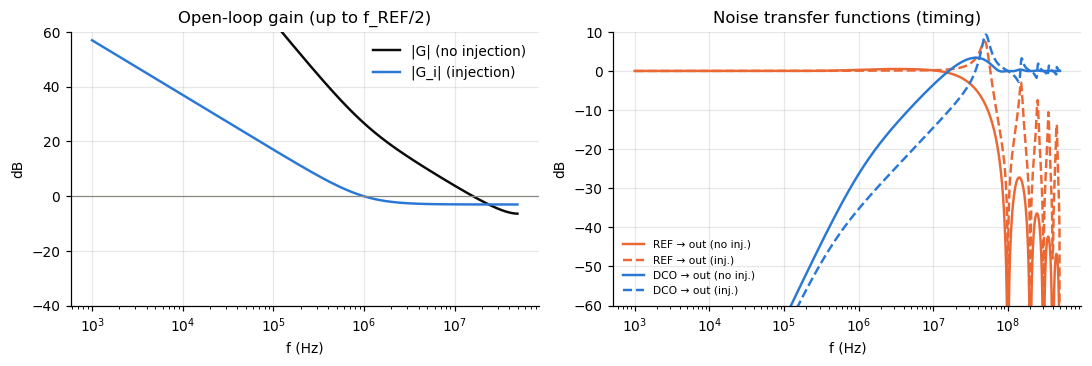

In [8]:
f = np.geomspace(1e3, cfg.f_out / 2, 800)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
G = LM[False].open_loop(f[f < cfg.f_ref / 2])
ax[0].semilogx(f[f < cfg.f_ref/2], 20*np.log10(np.abs(G)), color=COL["Total"], label="|G| (no injection)")
ax[0].semilogx(f[f < cfg.f_ref/2], 20*np.log10(np.abs(LM[True].open_loop(f[f < cfg.f_ref/2]))), color=COL["inj"], label="|G_i| (injection)")
ax[0].axhline(0, color=COL["free"], lw=0.8); ax[0].set_ylim(-40, 60)
ax[0].set_xlabel("f (Hz)"); ax[0].set_ylabel("dB"); ax[0].set_title("Open-loop gain (up to f_REF/2)"); ax[0].legend()
for name, fn, col in (("REF → out", "ntf_ref", COL["REF"]), ("DCO → out", "ntf_dco", COL["DCO"])):
    ax[1].semilogx(f, 20*np.log10(np.abs(getattr(LM[False], fn)(f))), color=col, label=name + " (no inj.)")
    ax[1].semilogx(f, 20*np.log10(np.abs(getattr(LM[True], fn)(f))), color=col, ls="--", label=name + " (inj.)")
ax[1].set_ylim(-60, 10); ax[1].set_xlabel("f (Hz)"); ax[1].set_ylabel("dB"); ax[1].set_title("Noise transfer functions (timing)")
ax[1].legend(fontsize=7)
fig.tight_layout(); save(fig, "loop_tf")

## 5. Phase-noise budget (linear model)

Output phase noise $\mathcal{L}(f) = \tfrac{1}{2}(2\pi f_0)^2 S_x(f)$, where $S_x$ is the sum of each source
times $|NTF|^2$: the reference (multiplied by $N^2$ in phase, i.e. unchanged in timing), the DCO, and the
quantization of the bang-bang detector and of the $\Delta\Sigma$. The deterministic part (limit cycle and
$\Delta\Sigma$ tones) is measured with a noise-free behavioral run.

| Mode | REF | DCO | BBPD (quantization) | ΔΣ (analytic) | Deterministic (noise-free sim.) | Total rms jitter (10 kHz – 100 MHz) |
|---|---|---|---|---|---|---|
| No injection | 413 fs | 1998 fs | 4285 fs | 168 fs | 3942 fs | 4746 fs |
| Injection | 799 fs | 1062 fs | 3792 fs | 197 fs | 2273 fs | 4018 fs |

Total = √(REF² + DCO² + max(BBPD, deterministic)²): the quantization error of the describing function and the limit cycle of the noise-free simulation are the same error of the sign() detector, so the larger one is kept. The deterministic part already contains the ΔΣ tones. Accuracy vs the behavioral model: 5–20 % while the loop is noise dominated (section 7).

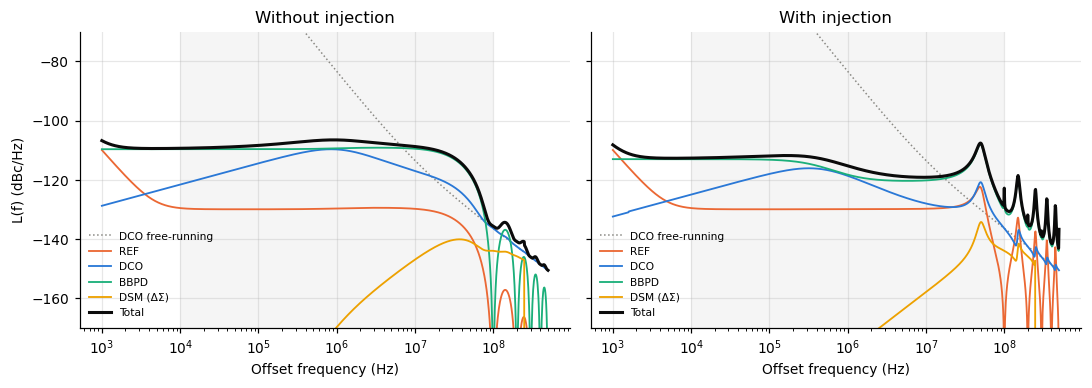

In [9]:
f = np.geomspace(1e3, cfg.f_out / 2, 1200)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
jit_rows = []
for a, inj in zip(ax, (False, True)):
    L = LM[inj].L_out(f)
    a.semilogx(f, LM[inj].L_free(f), color=COL["free"], lw=1, ls=":", label="DCO free-running")
    for k in ("REF", "DCO", "BBPD", "DSM"):
        a.semilogx(f, L[k], color=COL[k], lw=1.2, label=k + (" (ΔΣ)" if k == "DSM" else ""))
    a.semilogx(f, L["Total"], color=COL["Total"], lw=2, label="Total")
    a.axvspan(*JITTER_BAND, color="#000000", alpha=0.04, lw=0)
    a.set_ylim(-170, -70); a.set_xlabel("Offset frequency (Hz)")
    a.set_title("With injection" if inj else "Without injection"); a.legend(fontsize=7, loc="lower left")
    j = LM[inj].jitter(*JITTER_BAND)
    jit_rows.append(("Injection" if inj else "No injection", *[fs(j[k]) for k in ("REF", "DCO", "BBPD", "DSM", "Deterministic", "Total")]))
ax[0].set_ylabel("L(f) (dBc/Hz)")
fig.tight_layout(); save(fig, "pn_budget_linear")
table(jit_rows, ("Mode", "REF", "DCO", "BBPD (quantization)", "ΔΣ (analytic)", "Deterministic (noise-free sim.)",
                 f"Total rms jitter ({JITTER_BAND[0]/1e3:g} kHz – {JITTER_BAND[1]/1e6:g} MHz)"))
display(Markdown("Total = √(REF² + DCO² + max(BBPD, deterministic)²): the quantization error of the describing function "
                 "and the limit cycle of the noise-free simulation are the same error of the sign() detector, so the "
                 "larger one is kept. The deterministic part already contains the ΔΣ tones. Accuracy vs the behavioral "
                 "model: 5–20 % while the loop is noise dominated (section 7)."))

## 6. Behavioral time-domain model and validation

`pm.simulate` steps one DCO period at a time with the same integer arithmetic as the RTL (saturating PI
filter, filter→fine-code mapping, 1st-order $\Delta\Sigma$ clocked at $f_{OUT}/2$), the sign() detector, the
DCO noise (synthesized from the fitted $a/f^2 + b/f^3$), the reference noise and the detector noise, and
the injection as an edge replacement every REF period. The phase noise is the PSD of the timing error
of every output edge (Welch). Coarse/mid are fixed at the values of section 1.

| Mode | rms jitter (behavioral) | rms jitter (linear) | TIE rms | Period jitter rms | Cycle-to-cycle rms | σ_e (behavioral) | σ_e (linear) |
|---|---|---|---|---|---|---|---|
| No injection | 4880 fs | 4746 fs | 4921 fs | 1031 fs | 847 fs | 4.99 ps | 6.91 ps |
| Injection | 2460 fs | 4018 fs | 2781 fs | 1915 fs | 2844 fs | 6.06 ps | 9.39 ps |

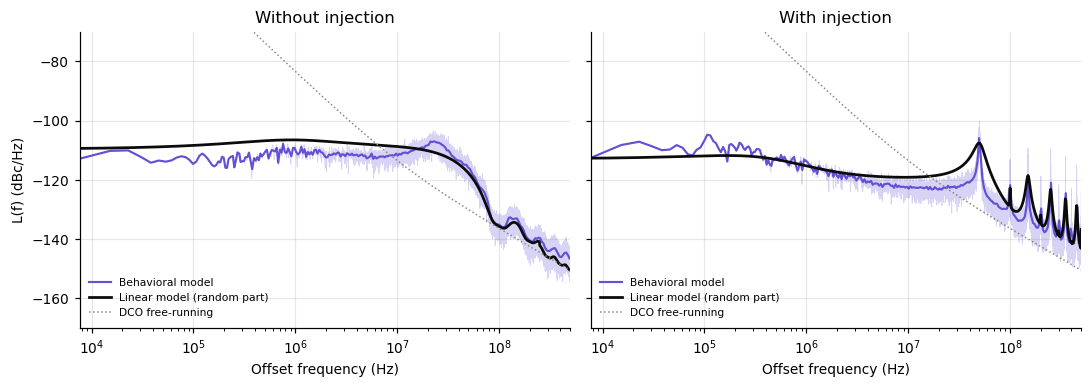

In [10]:
NREF = 1 << 16
def behav(c, noise=True, n=NREF, seed=1, **kw):
    kw.setdefault("pd_early_range", 0.5 / c.f_out)   # Symmetric detector (+/- T/2), as in il_dco.v
    r = pm.simulate(c, ch, COARSE, MID, n_ref=n, dco=DCO, ref=REF, noise=noise, seed=seed, **kw)
    x = r.x[len(r.x) // 8:]                      # Drop the initial settling
    fr, L = pm.phase_noise_from_tie(x, c.f_out, nperseg=min(1 << 17, len(x)))
    return r, x, fr, L

def smooth(fr, L, n=300):
    # Average of the power in log-spaced bins (for display; the jitter integrates the raw PSD)
    e = np.geomspace(fr[0], fr[-1], n + 1); i = np.digitize(fr, e)
    p = 10 ** (L / 10)
    k = [j for j in range(1, n + 1) if np.any(i == j)]
    return np.array([np.exp(np.mean(np.log(fr[i == j]))) for j in k]), np.array([10*np.log10(np.mean(p[i == j])) for j in k])

SIM = {inj: behav(replace(cfg, inj=inj)) for inj in (False, True)}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
rows = []
for a, inj in zip(ax, (False, True)):
    r, x, fr, L = SIM[inj]
    a.semilogx(fr, L, color=COL["sim"], lw=0.5, alpha=0.25)
    a.semilogx(*smooth(fr, L), color=COL["sim"], lw=1.4, label="Behavioral model")
    a.semilogx(f, LM[inj].L_out(f)["Total"], color=COL["Total"], lw=1.8, label="Linear model (random part)")
    a.semilogx(f, LM[inj].L_free(f), color=COL["free"], lw=1, ls=":", label="DCO free-running")
    a.set_xlim(fr[0], cfg.f_out/2); a.set_ylim(-170, -70); a.set_xlabel("Offset frequency (Hz)")
    a.set_title("With injection" if inj else "Without injection"); a.legend(fontsize=7, loc="lower left")
    jm = pm.jitter_metrics(x, cfg.f_out)
    rows.append(("Injection" if inj else "No injection", fs(pm.integrated_jitter(fr, L, *JITTER_BAND, cfg.f_out)),
                 fs(LM[inj].jitter(*JITTER_BAND)["Total"]), fs(jm["tie_rms"]), fs(jm["per_rms"]), fs(jm["c2c_rms"]),
                 ps(np.std(r.e[len(r.e)//8:])), ps(LM[inj].loop_metrics()["sigma_e"])))
ax[0].set_ylabel("L(f) (dBc/Hz)")
fig.tight_layout(); save(fig, "pn_behavioral")
table(rows, ("Mode", "rms jitter (behavioral)", "rms jitter (linear)", "TIE rms", "Period jitter rms",
             "Cycle-to-cycle rms", "σ_e (behavioral)", "σ_e (linear)"))

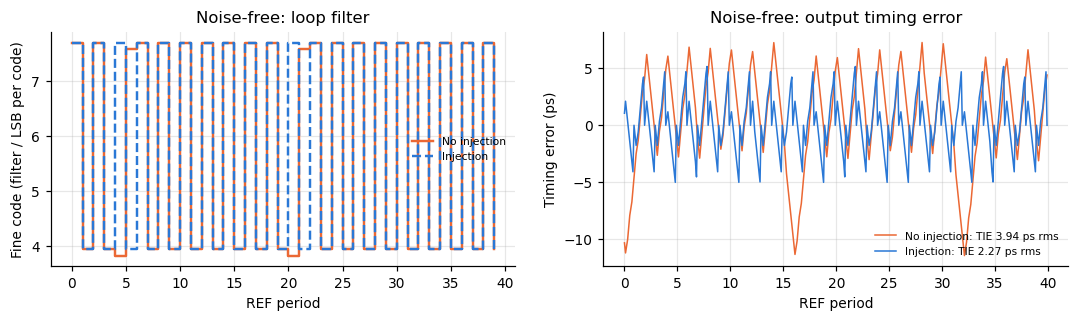

In [11]:
# Deterministic part: the same simulation without any noise source. A bang-bang loop with a large
# proportional step oscillates by itself (limit cycle); this jitter does not exist in the linear model.
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for inj in (False, True):
    r, x, *_ = behav(replace(cfg, inj=inj), noise=False, n=1 << 13)
    k = slice(len(r.filt) // 2, len(r.filt) // 2 + 40)
    ax[0].step(np.arange(40), r.filt[k] / cfg.code_lsb, where="post", color=COL["inj" if inj else "noinj"],
               ls="--" if inj else "-", label="Injection" if inj else "No injection")
    ax[1].plot(np.arange(400) / cfg.N, x[:400] * 1e12, color=COL["inj" if inj else "noinj"], lw=1,
               label=f"{'Injection' if inj else 'No injection'}: TIE {ps(np.std(x))} rms")
ax[0].set_xlabel("REF period"); ax[0].set_ylabel("Fine code (filter / LSB per code)"); ax[0].set_title("Noise-free: loop filter")
ax[1].set_xlabel("REF period"); ax[1].set_ylabel("Timing error (ps)"); ax[1].set_title("Noise-free: output timing error")
for a in ax: a.legend(fontsize=7)
fig.tight_layout(); save(fig, "limit_cycle")

### Validation against the RTL simulation

`test_pll_digital` simulates the RTL with the delay models made from the ngspice results (no noise), so it
is compared with the **noise-free** behavioral model. The edge log also gives, for each injection, the
difference between the natural DCO edge (`FINE_OUT` + $t_{mux}$) and the edge at `OUT`: the correction that
the injection applies. It has to stay well inside the window margins of section 3.

| Mode | LOCKED at | coarse/mid | f_OUT | Glitches after lock | TIE rms, RTL / behavioral (noise-free) | Injection correction (natural − injected) |
|---|---|---|---|---|---|---|
| No injection | 3.46 µs | 8/14 | 1.000000 GHz | 0 | 4.03 ps / 3.94 ps |  |
| Injection | 3.46 µs | 8/14 | 1.000000 GHz | 0 | 1.85 ps / 2.27 ps | 0.0736 ps ± 4.57 ps (max 4.98 ps) |

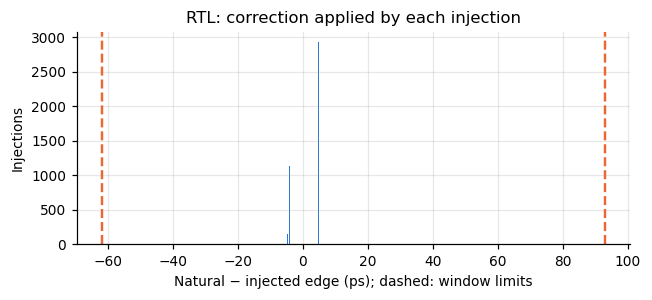

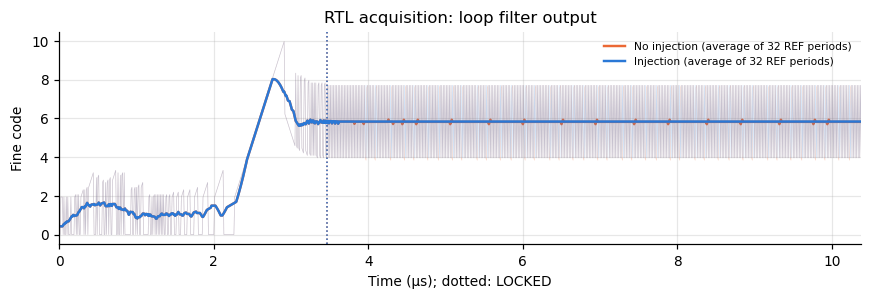

In [12]:
if not RTL:
    display(Markdown("> No RTL results: run `make -C sim PDK=%s test_pll_digital test_pll_digital_inj`" % PDK))
rows = []
for inj, r in RTL.items():
    if r["t_lock"] is None:
        rows.append(("Injection" if inj else "No injection", "**not locked**", "", "", "", "", "")); continue
    rb, xb, *_ = behav(replace(cfg, inj=inj), noise=False, n=1 << 13)
    corr = ""
    if inj and "natural_minus_out" in r:
        tn, d = r["natural_minus_out"]
        big = np.abs(d) > 1e-13
        corr = f"{ps(np.mean(d[big]))} ± {ps(np.std(d[big]))} (max {ps(np.max(np.abs(d)))})"
    rows.append(("Injection" if inj else "No injection", f"{r['t_lock']*1e6:.2f} µs",
                 f"{r.get('coarse')}/{r.get('mid')}", f"{r['f_out']/1e9:.6f} GHz", r["glitches"],
                 f"{ps(np.std(r['x']))} / {ps(np.std(xb))}", corr))
if rows:
    table(rows, ("Mode", "LOCKED at", "coarse/mid", "f_OUT", "Glitches after lock",
                 "TIE rms, RTL / behavioral (noise-free)", "Injection correction (natural − injected)"))
if True in RTL and "natural_minus_out" in RTL[True]:
    tn, d = RTL[True]["natural_minus_out"]
    big = np.abs(d) > 1e-13
    fig, a = plt.subplots(figsize=(6, 2.8))
    a.hist(d[big] * 1e12, bins=60, color=COL["inj"])
    a.axvline(-early * 1e12, color=COL["REF"], ls="--"); a.axvline(late * 1e12, color=COL["REF"], ls="--")
    a.set_xlabel("Natural − injected edge (ps); dashed: window limits"); a.set_ylabel("Injections")
    a.set_title("RTL: correction applied by each injection"); fig.tight_layout(); save(fig, "rtl_injection_correction")

# Acquisition in the RTL: fine code (loop filter output) vs time, with LOCKED and the start of the injection
if RTL:
    fig, a = plt.subplots(figsize=(8, 2.8))
    tmax = 3 * max(r["t_lock"] for r in RTL.values() if r["t_lock"]) if any(r["t_lock"] for r in RTL.values()) else None
    for inj, r in RTL.items():
        if "filter" not in r:
            continue
        # Filter output once per REF period (sampled just before each REF edge), and its moving average
        tr = np.arange(r["filter_t"][0], r["filter_t"][-1], 1 / cfg.f_ref)
        v = r["filter"][np.clip(np.searchsorted(r["filter_t"], tr) - 1, 0, None)] / cfg.code_lsb
        w = 32
        avg = np.convolve(v, np.ones(w) / w, mode="same")
        col = COL["inj" if inj else "noinj"]
        a.plot(tr * 1e6, v, color=col, lw=0.4, alpha=0.25)
        a.plot(tr * 1e6, avg, color=col, lw=1.6, label=("Injection" if inj else "No injection") + f" (average of {w} REF periods)")
        if r["t_lock"]:
            a.axvline(r["t_lock"] * 1e6, color=col, ls=":", lw=1)
    if tmax:
        a.set_xlim(0, tmax * 1e6)
    a.set_xlabel("Time (µs); dotted: LOCKED"); a.set_ylabel("Fine code"); a.set_title("RTL acquisition: loop filter output")
    a.legend(fontsize=7); fig.tight_layout(); save(fig, "rtl_acquisition")

## 7. Choosing KP and KI

The behavioral model is fast enough to sweep the loop gains. For each $K_P$ (with $K_I = K_P \cdot$ ratio)
the integrated jitter is computed with and without injection. Small $K_P$: the loop is too slow to
correct the DCO noise (and acquisition is slow). Large $K_P$: limit cycle and detector noise dominate.

| Optimized for | K_P | K_I | Jitter without injection | Jitter with injection |
|---|---|---|---|---|
| No injection | 2048 | 128 | 3320 fs | 1748 fs |
| Injection | 512 | 32 | 43561 fs | 1341 fs |
| Both modes (minimum of the sum) | 1448 | 90 | 3376 fs | 1559 fs |

Suggested setting: **K_P = 1448, K_I = 90** (currently 3967, 257). A smaller K_P also slows the phase acquisition: check the lock time with the RTL simulation (section 6).

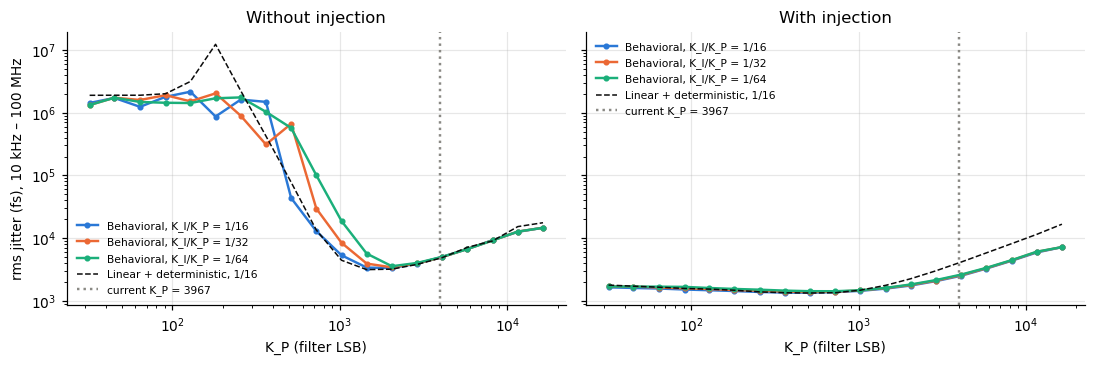

In [13]:
KPs = np.unique(np.round(np.geomspace(32, 16384, 19)).astype(int))
RATIOS = (1/16, 1/32, 1/64)
res = {}
for inj in (False, True):
    for ratio in RATIOS:
        for kp in KPs:
            c = replace(cfg, KP=int(kp), KI=max(1, int(round(kp * ratio))), inj=inj)
            _, x, fr, L = behav(c, n=1 << 15)
            res[(inj, ratio, kp)] = pm.integrated_jitter(fr, L, *JITTER_BAND, c.f_out)
            if ratio == RATIOS[0]:
                res[("lin", inj, kp)] = linear(c).jitter(*JITTER_BAND)["Total"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for a, inj in zip(ax, (False, True)):
    for ratio, col in zip(RATIOS, (COL["DCO"], COL["REF"], COL["BBPD"])):
        a.semilogx(KPs, [res[(inj, ratio, k)] * 1e15 for k in KPs], "o-", ms=3, color=col, label=f"Behavioral, K_I/K_P = 1/{int(1/ratio)}")
    a.semilogx(KPs, [res[("lin", inj, k)] * 1e15 for k in KPs], "--", color=COL["Total"], lw=1, label=f"Linear + deterministic, 1/{int(1/RATIOS[0])}")
    a.axvline(cfg.KP, color=COL["free"], ls=":", label=f"current K_P = {cfg.KP}")
    a.set_xlabel("K_P (filter LSB)"); a.set_title("With injection" if inj else "Without injection"); a.legend(fontsize=7)
ax[0].set_ylabel(f"rms jitter (fs), {JITTER_BAND[0]/1e3:g} kHz – {JITTER_BAND[1]/1e6:g} MHz")
fig.tight_layout(); save(fig, "kp_sweep")
a.set_yscale("log")
best_kp = {inj: min(((res[(inj, r, k)], k, r) for r in RATIOS for k in KPs)) for inj in (False, True)}
# One setting for both modes (the phase acquisition always runs without injection): minimum of the sum
best_kp["both"] = min(((res[(False, r, k)] + res[(True, r, k)], k, r) for r in RATIOS for k in KPs))
rows = []
for key, name in ((False, "No injection"), (True, "Injection"), ("both", "Both modes (minimum of the sum)")):
    j, k, r = best_kp[key]
    rows.append((name, k, max(1, int(round(k * r))), fs(res[(False, r, k)]), fs(res[(True, r, k)])))
table(rows, ("Optimized for", "K_P", "K_I", "Jitter without injection", "Jitter with injection"))
j, KP_OPT, R_OPT = best_kp["both"]; KI_OPT = max(1, int(round(KP_OPT * R_OPT)))
display(Markdown(f"Suggested setting: **K_P = {KP_OPT}, K_I = {KI_OPT}** (currently {cfg.KP}, {cfg.KI}). A smaller K_P also "
                 "slows the phase acquisition: check the lock time with the RTL simulation (section 6)."))

### Pull-in and gear shifting

A bang-bang loop has no frequency detector: after the coarse/mid acquisition (`freq_lock.v`, resolution
$1/N$) the fine loop must pull the frequency in with its own proportional and integral steps. The table
gives the largest initial fine-code error (relative to the code that gives $f_{OUT}$) from which the
noise-free behavioral model still locks. The integrator starts from 0 after the acquisition, so the
error can be as large as the target fine code. A low-jitter $K_P$ usually has a small pull-in range:
acquire with large gains and change `KP`/`KI` (top-level inputs) after `LOCKED` (gear shifting,
`-D TB_KP_LOCKED=... -D TB_KI_LOCKED=...` in `pll_test.v`).

In [14]:
codes = np.arange(len(ch.fine))
target = np.interp(1 / f0, [ch.period(COARSE_C, MID_C, c) for c in codes], codes)
offsets = np.array([-24, -16, -12, -8, -6, -4, -2, 2, 4, 6, 8, 12, 16, 24])
rows = []
for kp, ki in sorted({(KP_ACQ, KI_ACQ), (cfg.KP, cfg.KI), (KP_OPT, KI_OPT), (2048, 128), (1024, 64)}, reverse=True):
    ok = []
    for d in offsets:
        f_start = int(np.clip((target + d) * cfg.code_lsb, 0, (1 << cfg.filter_bits) - 1))
        if not (0 <= target + d <= len(ch.fine) - 1):
            ok.append(None); continue
        r = pm.simulate(replace(cfg, KP=kp, KI=ki), ch, COARSE_C, MID_C, n_ref=6000, filt0=f_start, noise=False,
                        pd_early_range=0.5 / f0)
        ok.append(abs(r.filt[-500:].mean() / cfg.code_lsb - target) < 1)
    neg = [d for d, o in zip(offsets, ok) if d < 0 and o is not None]
    pos = [d for d, o in zip(offsets, ok) if d > 0 and o is not None]
    lo = max([d for d, o in zip(offsets, ok) if d < 0 and o is False], default=None)
    hi = min([d for d, o in zip(offsets, ok) if d > 0 and o is False], default=None)
    fmt = lambda b, side: (f"fails at {b:+d}" if b is not None else f"OK (whole range, {side:+d})")
    rows.append((f"{kp} / {ki}", fmt(lo, min(neg) if neg else 0), fmt(hi, max(pos) if pos else 0)))
display(Markdown(f"Evaluated with coarse = {COARSE_C}, mid = {MID_C}, where f_OUT needs fine code {target:.1f} (middle of the range). "
                 f"The loop filter starts from 0 after the acquisition, so the initial error can be as large as −{len(ch.fine)-1} codes."))
table(rows, ("K_P / K_I", "Start below the target (DCO fast)", "Start above the target (DCO slow)"))

Evaluated with coarse = 8, mid = 13, where f_OUT needs fine code 11.8 (middle of the range). The loop filter starts from 0 after the acquisition, so the initial error can be as large as −31 codes.

| K_P / K_I | Start below the target (DCO fast) | Start above the target (DCO slow) |
|---|---|---|
| 3967 / 257 | OK (whole range, -8) | OK (whole range, +16) |
| 2048 / 128 | OK (whole range, -8) | OK (whole range, +16) |
| 1448 / 90 | OK (whole range, -8) | OK (whole range, +16) |
| 1024 / 64 | OK (whole range, -8) | OK (whole range, +16) |

## 8. Summary

In [15]:
r0, x0, fr0, L0 = SIM[False]; r1, x1, fr1, L1 = SIM[True]
lm0, lm1 = LM[False].loop_metrics(), LM[True].loop_metrics()
def Lat(fr, L, f): return f"{np.interp(np.log10(f), np.log10(fr), L):.1f} dBc/Hz"
rows = [
    ("Output frequency", f"{cfg.f_out/1e9:g} GHz (N = {cfg.N}, f_REF = {cfg.f_ref/1e6:g} MHz)", ""),
    ("DCO tuning range / fine resolution", f"{1/ch.period(15,15,31)/1e9:.2f} – {1/ch.period(0,0,0)/1e9:.2f} GHz / {Kdco/1e3:.0f} kHz", ""),
    ("DCO free-running L(1 MHz)", f"{10*np.log10(DCO.L(1e6)):.1f} dBc/Hz", dco_src.split(" (")[0]),
    ("Loop gains (acquisition → after LOCKED)", f"{KP_ACQ}/{KI_ACQ} → {cfg.KP}/{cfg.KI} (β_p = {ps(lm0['beta_p'])})", "pll_test.v"),
    ("Jitter-transfer bandwidth / peaking", f"{lm0['f_3dB']/1e6:.2f} MHz / {lm0['peaking_dB']:.2f} dB", "linear, no injection"),
    ("rms jitter, no injection", fs(pm.integrated_jitter(fr0, L0, *JITTER_BAND, cfg.f_out)) + f" ({JITTER_BAND[0]/1e3:g} kHz – {JITTER_BAND[1]/1e6:g} MHz)", "behavioral"),
    ("rms jitter, injection", fs(pm.integrated_jitter(fr1, L1, *JITTER_BAND, cfg.f_out)), "behavioral"),
    ("L(100 kHz) / L(1 MHz), no injection", f"{Lat(fr0, L0, 1e5)} / {Lat(fr0, L0, 1e6)}", "behavioral"),
    ("L(100 kHz) / L(1 MHz), injection", f"{Lat(fr1, L1, 1e5)} / {Lat(fr1, L1, 1e6)}", "behavioral"),
    ("Injection window margins (early / late)", f"{ps(early)} / {ps(late)} = {early/lm1['sigma_e']:.0f} / {late/lm1['sigma_e']:.0f} σ_e", "σ_e with the current K_P"),
]
for inj, r in RTL.items():
    rows.append((f"RTL, {'injection' if inj else 'no injection'}",
                 f"LOCKED at {r['t_lock']*1e6:.2f} µs, {r.get('glitches', '?')} glitches" if r["t_lock"] else "not locked", "iverilog"))
rows.append(("Suggested K_P / K_I (both modes)", f"{KP_OPT} / {KI_OPT} → {fs(res[(False, R_OPT, KP_OPT)])} / {fs(res[(True, R_OPT, KP_OPT)])} (no inj. / inj.)", "behavioral sweep"))
table(rows, ("Item", "Value", "From"))

| Item | Value | From |
|---|---|---|
| Output frequency | 1 GHz (N = 10, f_REF = 100 MHz) |  |
| DCO tuning range / fine resolution | 0.75 – 1.84 GHz / 414 kHz |  |
| DCO free-running L(1 MHz) | -83.4 dBc/Hz | ISF simulation |
| Loop gains (acquisition → after LOCKED) | 3967/257 → 3967/257 (β_p = 8.01 ps) | pll_test.v |
| Jitter-transfer bandwidth / peaking | 30.05 MHz / 0.51 dB | linear, no injection |
| rms jitter, no injection | 4880 fs (10 kHz – 100 MHz) | behavioral |
| rms jitter, injection | 2460 fs | behavioral |
| L(100 kHz) / L(1 MHz), no injection | -114.6 dBc/Hz / -108.5 dBc/Hz | behavioral |
| L(100 kHz) / L(1 MHz), injection | -106.7 dBc/Hz / -113.8 dBc/Hz | behavioral |
| Injection window margins (early / late) | 61.8 ps / 93 ps = 7 / 10 σ_e | σ_e with the current K_P |
| RTL, no injection | LOCKED at 3.46 µs, 0 glitches | iverilog |
| RTL, injection | LOCKED at 3.46 µs, 0 glitches | iverilog |
| Suggested K_P / K_I (both modes) | 1448 / 90 → 3376 fs / 1559 fs (no inj. / inj.) | behavioral sweep |

## Appendix: definitions and limitations

- **Timing error / TIE**: delay of each output edge with respect to an ideal clock at $N f_{REF}$.
  $\mathcal{L}(f) = \frac{1}{2}(2\pi f_0)^2 S_x(f)$ (single sideband, $S_x$ one-sided).
  **rms (absolute) jitter** $= \sqrt{2\int \mathcal{L}\,df}\,/\,(2\pi f_0)$ over the stated band.
  **Period jitter**: rms of $T_n - \bar T$. **Cycle-to-cycle**: rms of $T_{n+1}-T_n$.
- **Bang-bang detector**: describing function $K_{BB}=\sqrt{2/\pi}/\sigma_e$ (valid for a Gaussian error
  dominated by random noise). When $\beta_p \gtrsim \sigma_e$ the error is dominated by the limit cycle and
  the behavioral model must be used (sections 6–7).
- **Injection**: modeled as a full edge replacement ($\beta = 1$) every REF period, with the natural edge
  aligned to the injected one (which the symmetric SS-BBPD guarantees, see section 6 for the RTL check).
  The linear injection model neglects the aliasing of the DCO noise in the output spectrum.
- **Not modeled**: supply noise, the mismatch between the two mux paths (a static offset → a reference
  spur with injection), the metastability of the SS-BBPD, the coupling of REF into the DCO.
- **Assumed** (Setup cell): the reference phase noise and the SS-BBPD noise.
- References: Da Dalt, *A design-oriented study of the nonlinear dynamics of digital bang-bang PLLs*, TCAS-I 2005;
  Marucci et al., *Analysis and design of low-jitter digital bang-bang PLLs*, TCAS-I 2014;
  Hajimiri & Lee, *A general theory of phase noise in electrical oscillators*, JSSC 1998;
  Ye, Jansson & Galton, *A multiple-crystal interface PLL with VCO realignment*, JSSC 2002 (realignment model).